# 02 · Del dato al episodio: hallazgos y decisiones


In [1]:
import json
import sys
import warnings
from datetime import datetime
from pathlib import Path

RAIZ = Path.cwd().resolve()
while not (RAIZ / 'src' / 'config.py').exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from src import config, estilo
from src.db import consultar, hash_sql
from src.eda_tablas import (
    DICCIONARIO_COLUMNAS,
    agregar_porcentaje,
    calidad_segura,
    colores_tipo_visita,
    comparar_columnas,
    nombre_etapa,
    nombre_tipo_visita,
)
from src.episodios import (
    construir_episodios,
    contar_los_recortados,
    preparar_visitas,
    reportar_edades,
    resumen_sensibilidad,
    valores_comparables,
)
from src.estilo import fmt_decimal, fmt_entero, fmt_mes, fmt_pct
from src.graficos import (
    COLOR_BASE,
    COLOR_CONTEXTO,
    COLOR_HOSP,
    COLORES_GRUPO,
    ETIQUETAS_CORTAS_GRUPO,
    MARCADORES,
    TEXTO_SECUNDARIO,
    activar_formato_tablas,
    ancho_linea,
    aplicar_estilo,
    barras_top_n,
    etiquetas_directas,
    figura_top,
    guardar_figura,
    linea_umbral,
    titulo_hallazgo,
)
from src.privacidad import enmascarar_pequenos, suprimir_pequenos, tabla_segura

aplicar_estilo()
activar_formato_tablas()
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)

G1, G2, G3 = config.GRUPOS
OSCURO, MEDIO, CLARO = estilo.GRISES


def marcar_corte(ax):
    """Línea vertical en FECHA_CORTE_ANALISIS (D9)."""
    linea_umbral(ax, config.FECHA_CORTE_ANALISIS, 'Corte del análisis', destacada=False)

## 1. La visita no tiene duración

### Qué vimos
En `visit_occurrence`, `visit_end_datetime` es igual a `visit_start_datetime`: la visita no dice cuánto duró la permanencia en urgencias.

### Evidencia

,,n,n_sin_fin,pct_sin_fin,n_negativas,pct_negativas,n_cero,pct_cero,p10_h,p50_h,p90_h,p99_h
concepto_visita,tipo_visita,,,,,,,,,,,
581479,Ambulatory Rehabilitation Visit,1.089.461,<10,suprimido,<10,suprimido,1.089.461,"100,0",0,0,0,0
9203,Emergency Room Visit,598.088,<10,suprimido,<10,suprimido,598.088,"100,0",0,0,0,0
3045729,Treatment urgency {Diagnosis},17.858,<10,suprimido,<10,suprimido,17.858,"100,0",0,0,0,0
9201,Inpatient Visit,592,<10,suprimido,<10,suprimido,592,"100,0",0,0,0,0
0,No matching concept,<10,<10,suprimido,<10,suprimido,<10,suprimido,suprimido,suprimido,suprimido,suprimido


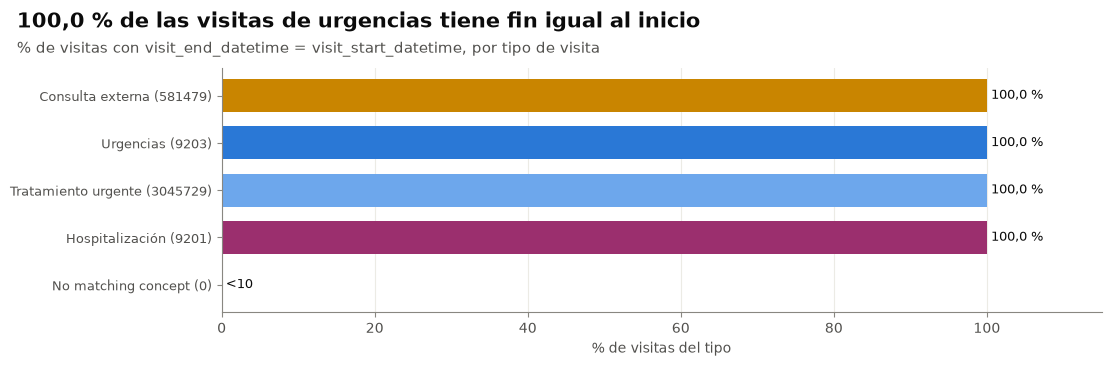

In [2]:
duracion_visitas = consultar('01_duracion_visitas').set_index(['concepto_visita', 'tipo_visita'])
display(tabla_segura(duracion_visitas))

datos = duracion_visitas.reset_index()
datos.index = [nombre_tipo_visita(c, n) for c, n in zip(datos['concepto_visita'], datos['tipo_visita'])]
serie = datos['pct_cero'].where(datos['n_cero'] >= config.MIN_CELDA).head(8)
urgencias = datos[datos['concepto_visita'] == config.CONCEPTO_URGENCIAS]
fig, ax = figura_top(len(serie))
barras_top_n(ax, serie, color=colores_tipo_visita(serie.index), n=len(serie), otros=False, formato=fmt_pct)
ax.set_xlabel('% de visitas del tipo')
if not urgencias.empty and urgencias['n_cero'].iloc[0] >= config.MIN_CELDA:
    titulo = f"{fmt_pct(urgencias['pct_cero'].iloc[0])} de las visitas de urgencias tiene fin igual al inicio"
else:
    titulo = 'Visitas con fin igual al inicio por tipo de visita'
titulo_hallazgo(fig, titulo, '% de visitas con visit_end_datetime = visit_start_datetime, por tipo de visita')
guardar_figura(fig, '02_visita_sin_duracion')
plt.show()

### Respuesta del hospital
El ingreso del paciente lo da `visit_occurrence.visit_start_datetime`.

### Decisión
**D5.** La llegada es `visit_start_datetime` y el LOS se reconstruye con las etapas de `visit_detail`: hospitalizado → `inicio_piso − llegada`; no hospitalizado → `fin_urg − llegada`, con `fin_urg` = máximo fin de las etapas no previas distintas de 9201.

## 2. Qué es cada etapa

### Qué vimos
Los nombres de las etapas en `concept` ("Emergency Room Visit", "Treatment urgency {Diagnosis}", "Inpatient Visit", "Ambulatory Rehabilitation Visit") no describen etapas de un proceso. Hay que entenderlas por su duración, por cuándo empiezan respecto a la llegada y por su orden.

### Evidencia
Duración por etapa, inicio respecto a la llegada, secuencias más comunes y transiciones entre etapas consecutivas.

In [3]:
duracion_etapas = consultar('01_duracion_etapas').set_index(['concepto_etapa', 'etapa'])
display(tabla_segura(duracion_etapas))

inicio_vs_llegada = consultar('01_inicio_etapas_vs_llegada').set_index(['concepto_etapa', 'etapa'])
display(tabla_segura(inicio_vs_llegada))

,,n,n_sin_fin,pct_sin_fin,n_negativas,pct_negativas,n_cero,pct_cero,p10_h,p25_h,p50_h,p75_h,p90_h,p99_h
concepto_etapa,etapa,,,,,,,,,,,,,
581479,Ambulatory Rehabilitation Visit,1.539.340,<10,suprimido,<10,suprimido,1.539.340,"100,0",0,0,0,0,0,0
3045729,Treatment urgency {Diagnosis},1.152.191,<10,suprimido,<10,suprimido,443.359,"38,5",0,0,"1,17","4,66","12,58","76,36"
9203,Emergency Room Visit,481.481,<10,suprimido,<10,suprimido,111.309,"23,1",0,"0,03","0,05","0,07","0,10","0,19"
9201,Inpatient Visit,108.601,<10,suprimido,<10,suprimido,3.533,"3,2","4,71","20,40","45,96","95,53","188,20","550,92"


,,n,n_igual_llegada,pct_igual_llegada,n_eventos_previos,pct_eventos_previos,p01_min,p05_min,p10_min,p50_min,p90_min,p99_min
concepto_etapa,etapa,,,,,,,,,,,
3045729,Treatment urgency {Diagnosis},855.250,<10,suprimido,118.405,"13,8","-29.373,21","-24.839,32","-22.787,76","4,53","353,80","3.395,90"
9203,Emergency Room Visit,419.140,373.567,"89,1",32.622,"7,8","-27.436,64","-23.253,12","-0,07",0,0,0
581479,Ambulatory Rehabilitation Visit,167.902,<10,suprimido,167.855,"100,0","-37.412,88","-30.690,72","-27.853,43","-24.093,49","-21.726,86","-20.621,07"
9201,Inpatient Visit,74.006,<10,suprimido,10.492,"14,2","-28.381,24","-23.269,84","-20.448,88","1.509,03","7.956,32","31.579,02"


,n_visitas,pct_visitas
secuencia,,
URG > MOV,266.745,"49,1"
MOV,144.877,"26,6"
URG,90.588,"16,7"
URG > MOV > PISO,28.474,"5,2"
MOV > PISO,12.340,"2,3"
PISO,356,"0,1"
URG > PISO,132,"0,0"
URG > MOV > URG,37,"0,0"
URG > MOV > AMB,32,"0,0"


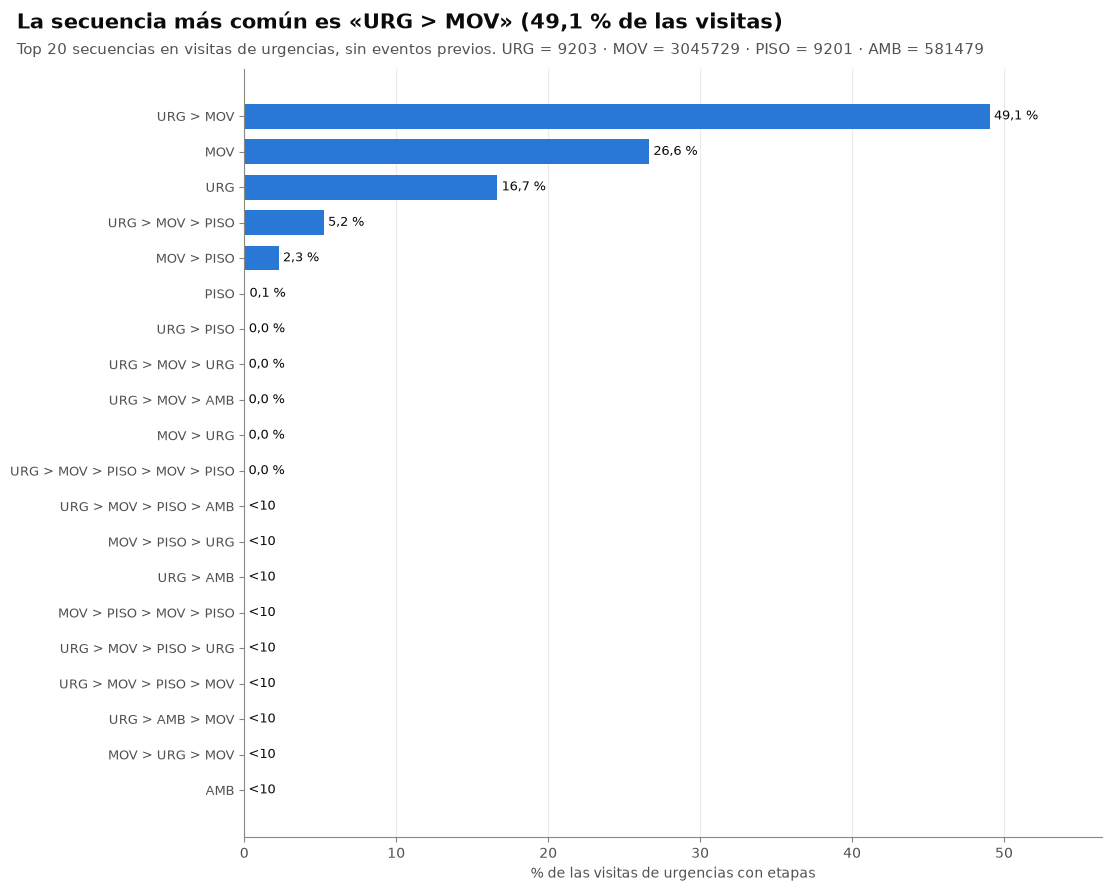

In [4]:
secuencias = consultar('02_secuencias_etapas').set_index('secuencia')
display(tabla_segura(secuencias))

serie = secuencias['pct_visitas'].where(secuencias['n_visitas'] >= config.MIN_CELDA)
fig, ax = figura_top(len(serie))
barras_top_n(ax, serie, color=estilo.AZUL, n=len(serie), otros=False, formato=fmt_pct)
ax.set_xlabel('% de las visitas de urgencias con etapas')
primera = serie.dropna()
titulo = (f'La secuencia más común es «{primera.index[0]}» ({fmt_pct(primera.iloc[0])} de las visitas)'
          if not primera.empty else 'Secuencias de etapas más comunes en urgencias')
titulo_hallazgo(fig, titulo, 'Top 20 secuencias en visitas de urgencias, sin eventos previos. URG = 9203 · MOV = 3045729 · PISO = 9201 · AMB = 581479')
guardar_figura(fig, '02_secuencias_etapas')
plt.show()

In [5]:
transiciones = consultar('01_transiciones').set_index(['concepto_origen', 'etapa_origen', 'concepto_destino', 'etapa_destino'])
tabla_segura(transiciones.head(15))

n n_gap_nulo pct_gap_nulo n_traslape pct_traslape  \
concepto_origen etapa_origen                    concepto_destino etapa_destino                                                                             
9203            Emergency Room Visit            3045729          Treatment urgency {Diagnosis}    295318        <10    suprimido     275780        93.38   
3045729         Treatment urgency {Diagnosis}   3045729          Treatment urgency {Diagnosis}    284257        <10    suprimido        511         0.18   
                                                9201             Inpatient Visit                   40874        <10    suprimido        212         0.52   
9201            Inpatient Visit                 9201             Inpatient Visit                   22149        <10    suprimido        198         0.89   
9203            Emergency Room Visit            9203             Emergency Room Visit                408        <10    suprimido        198        48.53   
                                                9201             Inpatient Visit                     132        <10    suprimido        <10    suprimido   
3045729         Treatment urgency {Diagnosis}   9203             Emergency Room Visit                 54        <10    suprimido         34        62.96   
                                                581479           Ambulatory Rehabilitation Visit      32        <10    suprimido        <10    suprimido   
9201            Inpatient Visit                 3045729          Treatment urgency {Diagnosis}        23        <10    suprimido        <10    suprimido   
                                                9203             Emergency Room Visit                 13        <10    suprimido         13        100.0   
                                                581479           Ambulatory Rehabilitation Visit     <10        <10    suprimido        <10    suprimido   
9203            Emergency Room Visit            581479           Ambulatory Rehabilitation Visit     <10        <10    suprimido        <10    suprimido   
581479          Ambulatory Rehabilitation Visit 3045729          Treatment urgency {Diagnosis}       <10        <10    suprimido        <10    suprimido   
                                                9201             Inpatient Visit                     <10        <10    suprimido        <10    suprimido   

                                                                                                 n_contiguas pct_contiguas p10_gap_min p50_gap_min p90_gap_min  
concepto_origen etapa_origen                    concepto_destino etapa_destino                                                                                  
9203            Emergency Room Visit            3045729          Treatment urgency {Diagnosis}         17363          5.88       -0.03       -0.02       -0.02  
3045729         Treatment urgency {Diagnosis}   3045729          Treatment urgency {Diagnosis}        272631         95.91         0.0         0.0         0.0  
                                                9201             Inpatient Visit                       32072         78.47         0.0         0.0     1308.23  
9201            Inpatient Visit                 9201             Inpatient Visit                       21806         98.45         0.0         0.0         0.0  
9203            Emergency Room Visit            9203             Emergency Room Visit                    210         51.47   -15841.44         0.0         0.0  
                                                9201             Inpatient Visit                         <10     suprimido      143.34      818.79    14023.06  
3045729         Treatment urgency {Diagnosis}   9203             Emergency Room Visit                     20         37.04   -16033.34     -870.57         0.0  
                                                581479           Ambulatory Rehabilitation Visit         <10     suprimido     1035.53     10562.9    31842.9

### Respuesta del hospital

| concept_id | Nombre en `concept` | Como tipo de visita | Como etapa (`visit_detail`) |
|---|---|---|---|
| 9203 | Emergency Room Visit | Urgencias | Ingreso al hospital por urgencias |
| 3045729 | Treatment urgency {Diagnosis} | Marginal | Cada movimiento o etapa del paciente en el hospital |
| 9201 | Inpatient Visit | Marginal | Hospitalización en piso |
| 581479 | Ambulatory Rehabilitation Visit | Consulta externa | Ingreso ambulatorio (p. ej., cita programada) |

### Decisión
El ingreso por urgencias (9203) y los movimientos (3045729) son tiempo en urgencias; el primer 9201 no previo marca la salida de urgencias hacia piso (D3, D5). La etapa 581479 dura 0 y no aporta tiempo.

## 3. Etapas anteriores a la llegada

### Qué vimos
Hay etapas que empiezan entre 14 y 27 días antes de la llegada (pico en 15–16 días, referencia de DBeaver). Entre ellas hay registros 9201 (hospitalización en piso) que, si se usaran, marcarían como hospitalizados a pacientes que no lo fueron en ese episodio.

### Evidencia

concepto_etapa,Ingreso ambulatorio (581479),Movimiento o etapa (3045729),Ingreso por urgencias (9203),Hospitalización en piso (9201)
dias_antes_llegada,,,,
0,<10,<10,<10,26
1,<10,<10,<10,34
2,<10,<10,<10,39
3,<10,<10,<10,36
4,<10,10,<10,50
5,<10,14,<10,61
6,<10,19,<10,85
7,<10,23,<10,94
8,25,43,<10,124


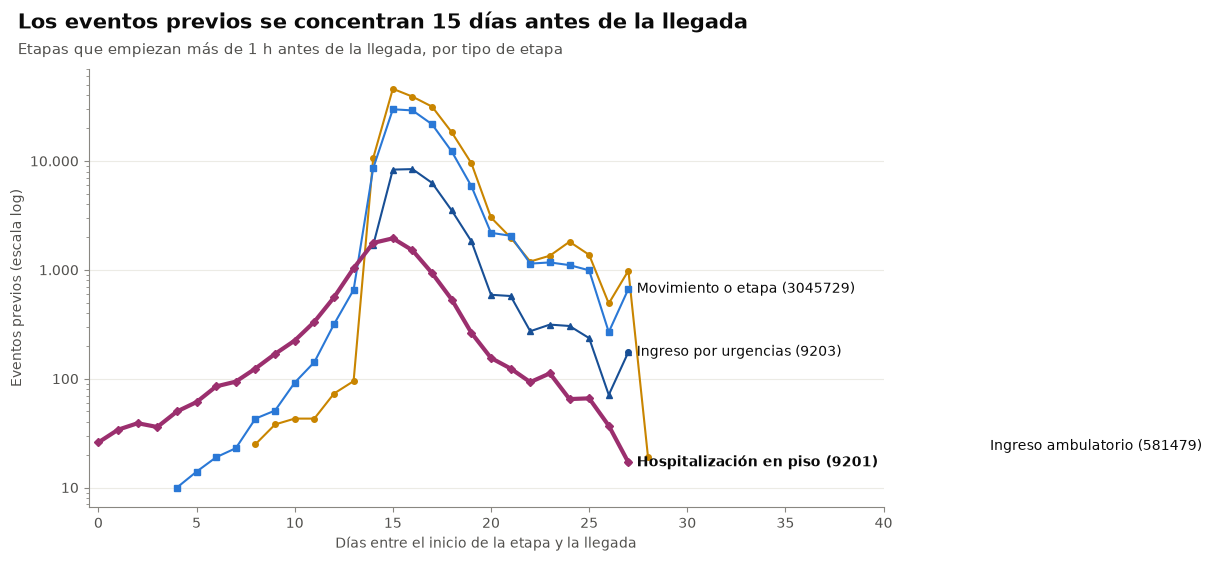

In [6]:
dias_previos = consultar('02_eventos_previos_dias')
matriz_dias = dias_previos.pivot_table(index='dias_antes_llegada', columns='concepto_etapa', values='n_etapas', aggfunc='sum', fill_value=0)
matriz_dias = matriz_dias[matriz_dias.sum().sort_values(ascending=False).index]
display(suprimir_pequenos(matriz_dias.rename(columns=nombre_etapa), [nombre_etapa(c) for c in matriz_dias.columns]))

grafico_dias = enmascarar_pequenos(matriz_dias, matriz_dias)
fig, ax = plt.subplots(figsize=(12, 5.5))
for i, concepto in enumerate(grafico_dias.columns[:4]):
    es_piso = concepto == config.CONCEPTO_PISO
    color = estilo.COLOR_ETAPA.get(int(concepto), MEDIO)
    ax.plot(grafico_dias.index, grafico_dias[concepto], marker=MARCADORES[i], markersize=4, color=color,
            linewidth=3 if es_piso else 1.5)
    etiquetas_directas(ax, grafico_dias.index, {nombre_etapa(concepto): (grafico_dias[concepto], color)},
                       negrita=[nombre_etapa(config.CONCEPTO_PISO)])
ax.set_yscale('log')
ax.set_xlim(-0.5, min(40, grafico_dias.index.max() + 0.5))
ax.set_xlabel('Días entre el inicio de la etapa y la llegada')
ax.set_ylabel('Eventos previos (escala log)')
por_dia = matriz_dias.sum(axis=1)
por_dia = por_dia[por_dia.index >= 1]
titulo = (f'Los eventos previos se concentran {fmt_entero(por_dia.idxmax())} días antes de la llegada'
          if not por_dia.empty else 'Eventos previos por días antes de la llegada')
titulo_hallazgo(fig, titulo, 'Etapas que empiezan más de 1 h antes de la llegada, por tipo de etapa')
guardar_figura(fig, '02_eventos_previos_dias')
plt.show()

Análisis de los 9201 previos: ¿terminan antes de la llegada (hospitalización previa completa) o siguen abiertos? Se reproduce la consulta de DBeaver (referencia: 10.492 registros; 96 % terminan antes, con mediana de 13,2 días entre su fin y la llegada y duración mediana de 44,7 h; 1,4 % tiene otra visita propia cerca; 4 % siguen abiertos con duración mediana de 383 h). "Otra visita cerca" se define aquí como otra visita del mismo paciente que empieza a ± 24 h del inicio del 9201.

,n,pct_del_total,p10_dias_fin_a_llegada,p50_dias_fin_a_llegada,p90_dias_fin_a_llegada,p10_duracion_h,p50_duracion_h,p90_duracion_h,n_fin_30d,pct_fin_30d,n_visita_cerca,pct_visita_cerca
categoria,,,,,,,,,,,,
termina_antes,10.061,"95,9","6,80","13,16","17,27","4,72","44,71","157,29",10.061,"100,0",138,"1,4"
sigue_abierta,431,"4,1","-15,96","-3,66","-0,32","133,26","382,58","657,88",<10,suprimido,15,"3,5"


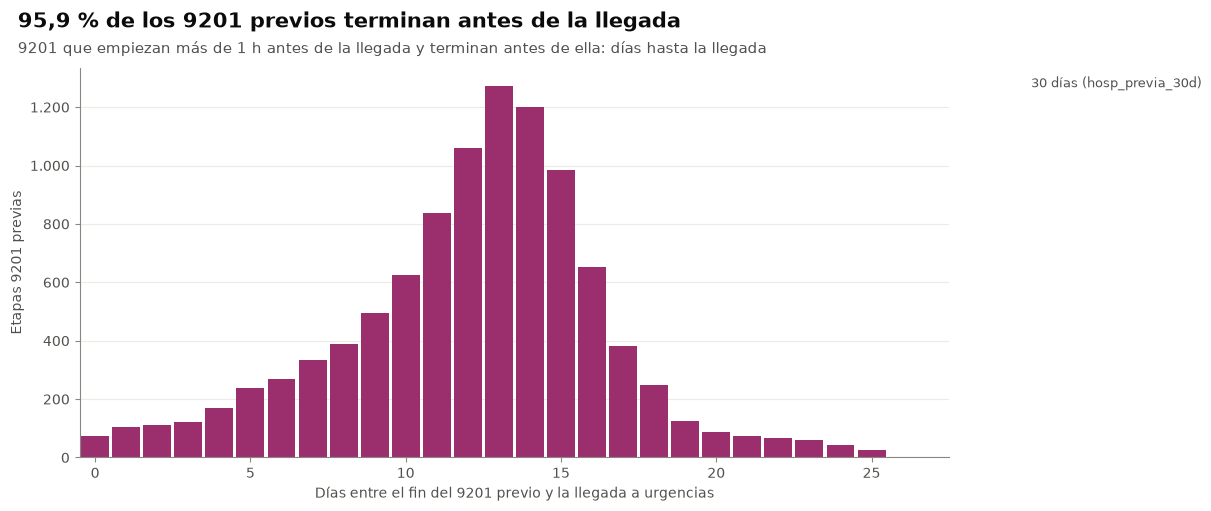

In [7]:
previos_9201 = consultar('02_eventos_previos_9201').set_index('categoria')
display(tabla_segura(previos_9201))

dias_9201 = consultar('02_eventos_previos_9201_dias').set_index('dias_fin_a_llegada')['n_etapas']
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(dias_9201.index, enmascarar_pequenos(dias_9201, dias_9201), width=0.9, color=COLOR_HOSP)
linea_umbral(ax, config.VENTANA_HOSP_PREVIA.days, '30 días (hosp_previa_30d)', destacada=False)
ax.set_xlim(-0.5, min(60, dias_9201.index.max() + 0.5))
ax.set_xlabel('Días entre el fin del 9201 previo y la llegada a urgencias')
ax.set_ylabel('Etapas 9201 previas')
if 'termina_antes' in previos_9201.index and previos_9201.loc['termina_antes', 'n'] >= config.MIN_CELDA:
    titulo = f"{fmt_pct(previos_9201.loc['termina_antes', 'pct_del_total'])} de los 9201 previos terminan antes de la llegada"
else:
    titulo = 'Hospitalizaciones previas: tiempo hasta la nueva llegada'
titulo_hallazgo(fig, titulo, '9201 que empiezan más de 1 h antes de la llegada y terminan antes de ella: días hasta la llegada')
guardar_figura(fig, '02_eventos_previos_9201_dias')
plt.show()

### Respuesta del hospital
Las fechas **no están corridas**. Son eventos previos asociados a la visita.

### Decisión
- **D2.** Una etapa con `visit_detail_start_datetime < visit_start_datetime − 1 h` es un **evento previo asociado a la visita**. Se excluye de los tiempos y de la definición de hospitalización.
- **D3.** Un episodio está hospitalizado si tiene al menos un 9201 que **no** es evento previo; `inicio_piso` es el primero de ellos. Si `inicio_piso` es anterior a la llegada (dentro de la tolerancia de 1 h), el LOS se recorta a 0 y se cuentan los casos (sección 8).
- **D11.** Como los 9201 previos son en su mayoría hospitalizaciones previas completas (reingresos), se usan para la variable `hosp_previa_30d`: algún 9201 previo cuyo fin está en los 30 días antes de la llegada.

## 4. Visitas partidas

### Qué vimos
Un mismo paso por urgencias aparece partido en varias visitas 9203 del mismo paciente, muy cercanas en el tiempo.

### Evidencia
Intervalo entre visitas de urgencias consecutivas del mismo paciente, desde el fin de la anterior hasta la llegada de la siguiente. Si la distribución se quiebra cerca de 1 hora, ese es el umbral natural de fusión.

duracion_previa,corta,larga,sin_fin
categoria,,,
00 misma llegada,30.282,32.497,9.174
01 traslapada,822,18.820,<10
02 0-10 min,10.476,3.191,3.305
03 10-20 min,4.633,1.407,1.353
04 20-30 min,2.758,952,701
05 30-45 min,2.318,918,619
06 45-60 min,1.398,549,361
07 60-90 min,1.426,514,364
08 90-120 min,571,278,146


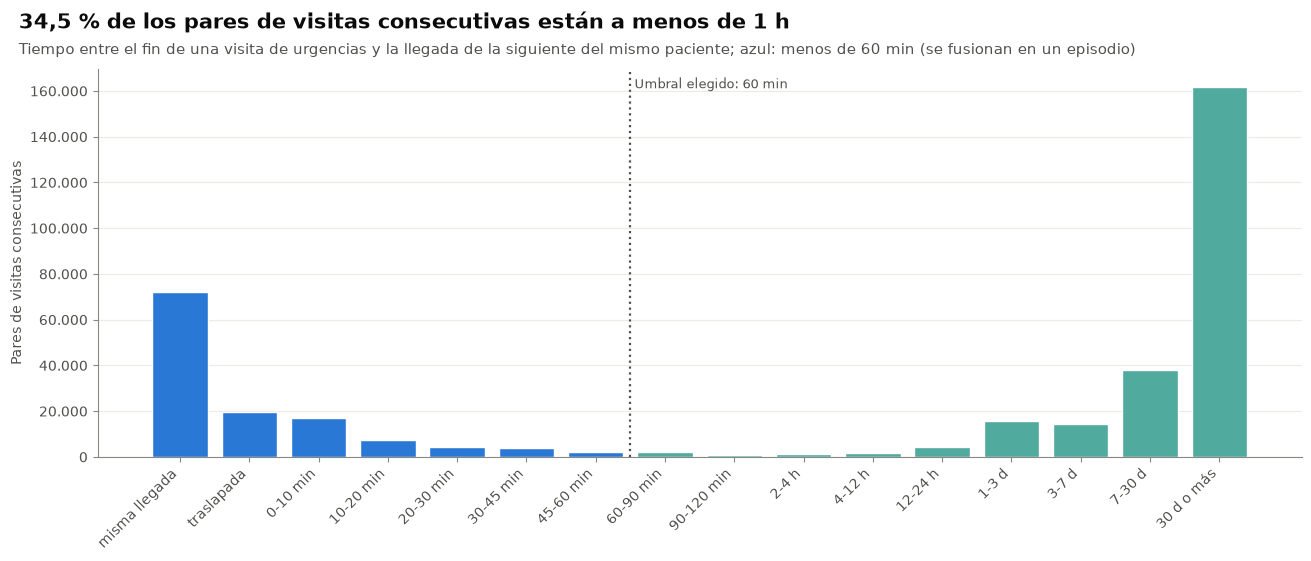

In [8]:
gaps = consultar('01_gap_visitas_consecutivas')
matriz_gaps = gaps.pivot_table(index='categoria', columns='duracion_previa', values='n_pares', aggfunc='sum', fill_value=0).sort_index()
display(suprimir_pequenos(matriz_gaps, list(matriz_gaps.columns)))

categorias = list(matriz_gaps.index)
total = matriz_gaps.sum(axis=1)
menos_1h = [c < '07' for c in categorias]  # categorías 00 a 06: misma llegada, traslape y < 60 min
valores = enmascarar_pequenos(total, total)
fig, ax = plt.subplots(figsize=(13, 5.5))
ax.bar(range(len(total)), valores, color=[estilo.AZUL if m else estilo.FAMILIAS['general']['claro'] for m in menos_1h], edgecolor='white', linewidth=1)
corte_1h = next((i for i, m in enumerate(menos_1h) if not m), None)
if corte_1h is not None:
    linea_umbral(ax, corte_1h - 0.5, 'Umbral elegido: 60 min')
ax.set_xticks(range(len(total)), [c.split(' ', 1)[1] for c in categorias], rotation=45, ha='right')
ax.set_ylabel('Pares de visitas consecutivas')
pct_menos_1h = 100 * total[menos_1h].sum() / total.sum()
titulo_hallazgo(fig, f'{fmt_pct(pct_menos_1h)} de los pares de visitas consecutivas están a menos de 1 h',
                'Tiempo entre el fin de una visita de urgencias y la llegada de la siguiente del mismo paciente; azul: menos de 60 min (se fusionan en un episodio)')
guardar_figura(fig, '02_visitas_partidas')
plt.show()

### Respuesta del hospital
Probablemente son errores de registro.

### Decisión
**D4.** Las visitas 9203 del mismo paciente, ordenadas por llegada (desempate por `visit_occurrence_id`), forman un episodio si la llegada de la siguiente es ≤ (máximo fin acumulado de las anteriores del episodio) + umbral. Umbral de **60 min**, con sensibilidad a 30 y 120 min (sección 8).

## 5. Visitas sin etapas y contactos breves

Muchas visitas de urgencias no tienen ninguna etapa, o solo tienen eventos previos. Además, una gran parte de los episodios no hospitalizados dura menos de 5 minutos.

Duración `fin_urg − llegada` de las visitas de urgencias, en tramos. Los tramos en gris quedan en el grupo 1 (contacto breve), los azules en el grupo 2 y las hospitalizadas en el grupo 3.

,n_visitas,pct_visitas
tramo,,
00 sin etapas,54.440,"9,1"
03 0 min,88.737,"14,8"
04 0-1 min,172,"0,0"
05 1-2 min,10.235,"1,7"
06 2-5 min,172.441,"28,8"
07 5-15 min,54.576,"9,1"
08 15-30 min,1.976,"0,3"
09 30-60 min,3.827,"0,6"
10 1-4 h,22.994,"3,8"


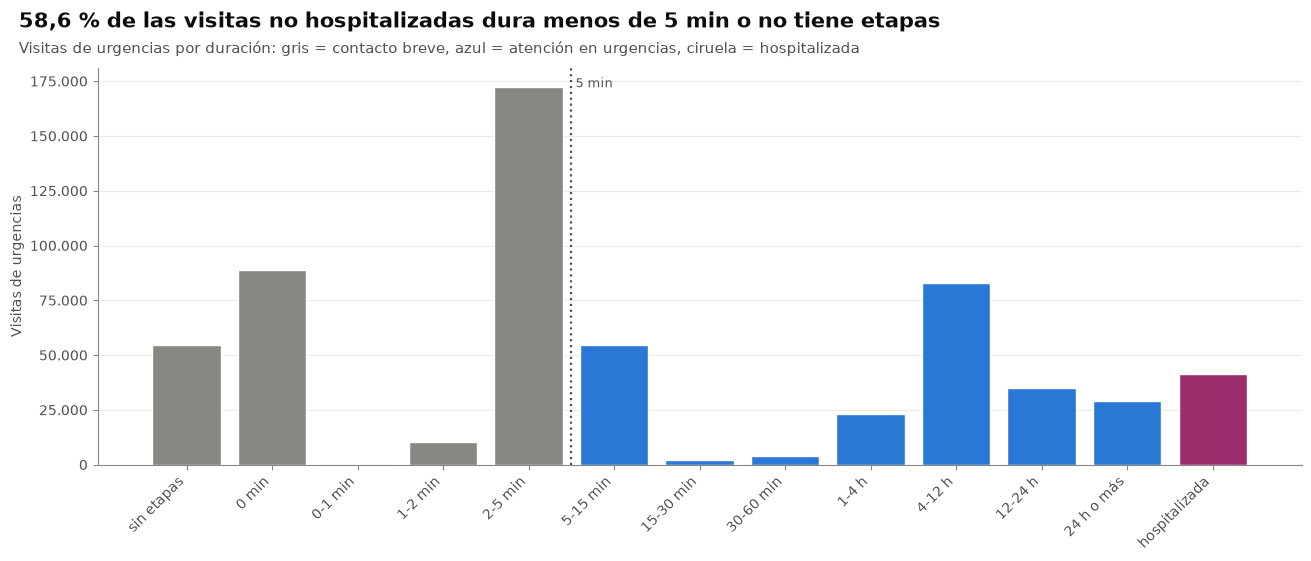

In [9]:
duracion_no_hosp = consultar('02_duracion_no_hosp').set_index('tramo')
display(tabla_segura(agregar_porcentaje(duracion_no_hosp, 'n_visitas')))

codigos = [t.split(' ', 1)[0] for t in duracion_no_hosp.index]
colores = [COLOR_HOSP if c == '99' else (COLOR_CONTEXTO if c < '07' else COLOR_BASE) for c in codigos]
valores = enmascarar_pequenos(duracion_no_hosp['n_visitas'], duracion_no_hosp['n_visitas'])
fig, ax = plt.subplots(figsize=(13, 5.5))
x = np.arange(len(valores))
ax.bar(x, valores, color=colores, edgecolor='white', linewidth=1)
corte_5min = next((i for i, c in enumerate(codigos) if c >= '07'), None)
if corte_5min is not None:
    linea_umbral(ax, corte_5min - 0.5, '5 min')
ax.set_xticks(x, [t.split(' ', 1)[1] for t in duracion_no_hosp.index], rotation=45, ha='right')
ax.set_ylabel('Visitas de urgencias')
no_hosp = duracion_no_hosp[[c != '99' for c in codigos]]
breves = no_hosp[[c < '07' for c in codigos if c != '99']]
titulo_hallazgo(fig, f"{fmt_pct(100 * breves['n_visitas'].sum() / no_hosp['n_visitas'].sum())} de las visitas no hospitalizadas dura menos de 5 min o no tiene etapas",
                'Visitas de urgencias por duración: gris = contacto breve, azul = atención en urgencias, ciruela = hospitalizada')
guardar_figura(fig, '02_duracion_visitas_grupos')
plt.show()

### Respuesta del hospital
Las Visitas sin etapas son generalmente casos en el paciente se va a casa de inmediato, es decir, generalmente son triage 4–5 o registros administrativos.

### Decisión
- **D10.** Las visitas sin etapas (o solo con eventos previos) se incluyen, con `fin = fin_urg = llegada`.
- **D6.** Tres grupos, evaluados en este orden: `1_contacto_breve` (no hospitalizado y LOS < 5 min, o sin ninguna etapa no previa); `2_atencion_urgencias` (no hospitalizado, LOS ≥ 5 min); `3_hospitalizado`. Los tiempos solo se analizan en los grupos 2 y 3.

## 6. Información inexistente

### Qué vimos
No hay triage, sección o servicio de urgencias, destino al egreso ni fallecimientos. Varias columnas del diccionario no existen en la base y `procedure_date` está vacía.

### Evidencia

In [10]:
columnas_reales = consultar('01t_columnas_reales')
faltantes = pd.concat(
    {tabla: comparar_columnas(columnas_reales, tabla) for tabla in DICCIONARIO_COLUMNAS}, names=['tabla']
)
display(suprimir_pequenos(faltantes[faltantes['estado'] == 'falta en la base'], []))

calidad_procedimientos = calidad_segura(consultar('01t_procedure_calidad'))['columnas']
calidad_procedimientos.loc[['procedure_date']]

tipo_dato            estado
tabla                columna                                                  
visit_occurrence     visit_type_concept_id                 —  falta en la base
                     preceding_visit_occurrence_id         —  falta en la base
procedure_occurrence procedure_datetime                    —  falta en la base
                     procedure_type_concept_id             —  falta en la base
measurement          unit_concept_id                       —  falta en la base
                     measurement_type_concept_id           —  falta en la base

,n,n_nulos,pct_nulos,valores_distintos,constante
columna,,,,,
procedure_date,47.042.032,47.042.032,"100,0",NaN,sí


### Respuesta del hospital
No existe información de triage, sección ni destino al egreso, tampoco de fallecimientos.

### Decisión: limitaciones

| Información que falta | Consecuencia para el análisis |
|---|---|
| Triage | No se puede ajustar el LOS por gravedad; los contactos breves (grupo 1) mezclan triage 4–5 y registros administrativos. |
| Sección o servicio de urgencias | No se puede ubicar dónde se acumula la espera dentro de urgencias. |
| Destino al egreso | Para los no hospitalizados no se sabe si fueron a casa, remitidos o se fueron sin ser atendidos. |
| Fallecimientos | No se puede analizar mortalidad; una ausencia de reconsulta no implica buena evolución. |
| Fechas de procedimientos (`procedure_date`) | Los procedimientos no sirven para medir tiempos de proceso; solo se usan como marca (D11). |
| Columnas del diccionario que no existen | `preceding_visit_occurrence_id`, `visit_type_concept_id`, `procedure_datetime`, `procedure_type_concept_id`, `unit_concept_id`, `measurement_type_concept_id`: la fusión de visitas se construye con D4. |

## 7. Completitud temporal

### Qué vimos
Desde abril de 2026 los datos están incompletos: las visitas de urgencias sin ninguna etapa pasan de ~8–10 % a 22–24 % por mes, y los episodios con atención caen a la mitad en mayo–junio de 2026. Julio de 2026 está incompleto y agosto casi vacío (referencias de DBeaver).

### Evidencia

,n,n_sin_etapas,pct_sin_etapas,n_solo_eventos_previos,pct_solo_eventos_previos,n_hospitalizadas,pct_hospitalizadas,n_atencion,pct_atencion
mes,,,,,,,,,
2023-01-01,16.734,1.394,"8,3",10,"0,1",1.125,"6,7",5.053,"30,2"
2023-02-01,14.802,1.219,"8,2",34,"0,2",941,"6,4",4.621,"31,2"
2023-03-01,17.256,1.409,"8,2",35,"0,2",1.101,"6,4",5.818,"33,7"
2023-04-01,16.066,1.240,"7,7",25,"0,2",1.094,"6,8",5.267,"32,8"
2023-05-01,18.302,1.562,"8,5",33,"0,2",1.086,"5,9",5.455,"29,8"
2023-06-01,16.599,1.500,"9,0",17,"0,1",1.055,"6,4",5.377,"32,4"
2023-07-01,16.300,1.300,"8,0",28,"0,2",1.063,"6,5",5.585,"34,3"
2023-08-01,16.231,1.253,"7,7",16,"0,1",1.080,"6,7",5.722,"35,2"
2023-09-01,15.068,1.253,"8,3",17,"0,1",985,"6,5",5.443,"36,1"


/var/home/luencaro/Programing/College/2026-30/Data Challenge HUN/patient-flow-HUN/src/graficos.py:625: UserWarning: Figura 02_completitud_mensual: 1 pares de textos superpuestos, por ejemplo «Sin etapas» y «Corte del análisis».
  revisar_solapes(fig, nombre)


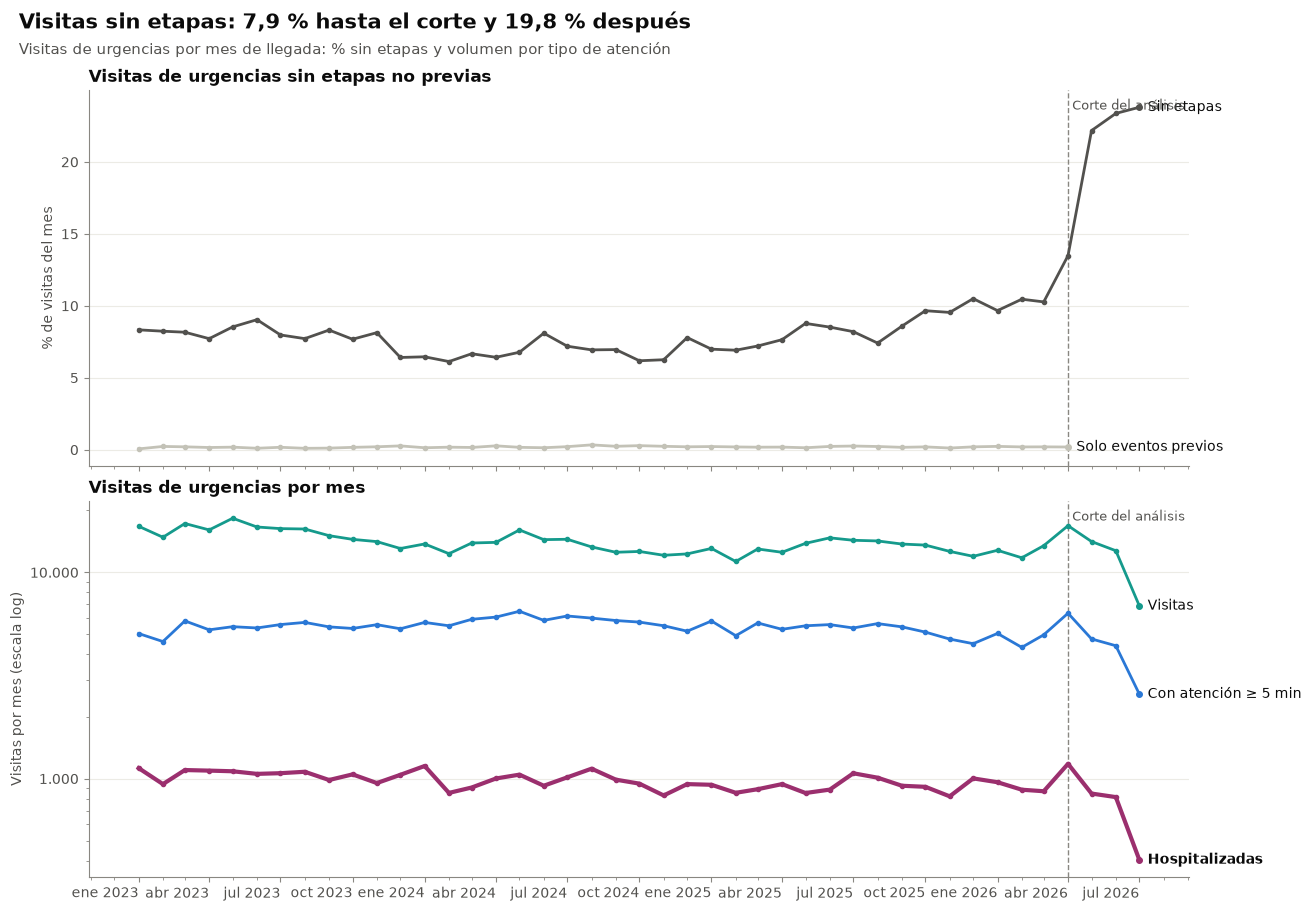

In [11]:
completitud = consultar('02_completitud_mensual')
completitud['mes'] = pd.to_datetime(completitud['mes'])
completitud = completitud.set_index('mes')
display(tabla_segura(completitud))

fig, ejes = plt.subplots(2, 1, figsize=(13, 9), sharex=True)
for columna, conteo, texto, color in [
    ('pct_sin_etapas', 'n_sin_etapas', 'Sin etapas', OSCURO),
    ('pct_solo_eventos_previos', 'n_solo_eventos_previos', 'Solo eventos previos', CLARO),
]:
    valores = completitud[columna].where(completitud[conteo] >= config.MIN_CELDA)
    ejes[0].plot(completitud.index, valores, marker='o', markersize=3, color=color)
    etiquetas_directas(ejes[0], completitud.index, {texto: (valores, color)})
ejes[0].set_ylabel('% de visitas del mes')
ejes[0].set_title('Visitas de urgencias sin etapas no previas')
for columna, texto, color in [('n', 'Visitas', estilo.VERDE), ('n_atencion', 'Con atención ≥ 5 min', COLOR_BASE),
                              ('n_hospitalizadas', 'Hospitalizadas', COLOR_HOSP)]:
    valores = enmascarar_pequenos(completitud[columna], completitud[columna])
    ejes[1].plot(completitud.index, valores, marker='o', markersize=3, color=color,
                 linewidth=3 if columna == 'n_hospitalizadas' else 2)
    etiquetas_directas(ejes[1], completitud.index, {texto: (valores, color)}, negrita=['Hospitalizadas'])
ejes[1].set_yscale('log')
ejes[1].set_ylabel('Visitas por mes (escala log)')
ejes[1].set_title('Visitas de urgencias por mes')
for ax in ejes:
    marcar_corte(ax)
antes = completitud[completitud.index <= config.FECHA_CORTE_ANALISIS]
despues = completitud[completitud.index > config.FECHA_CORTE_ANALISIS]
if not despues.empty:
    titulo = (f"Visitas sin etapas: {fmt_pct(100 * antes['n_sin_etapas'].sum() / antes['n'].sum())} hasta el corte "
              f"y {fmt_pct(100 * despues['n_sin_etapas'].sum() / despues['n'].sum())} después")
else:
    titulo = 'Completitud mensual de las visitas de urgencias'
titulo_hallazgo(fig, titulo, 'Visitas de urgencias por mes de llegada: % sin etapas y volumen por tipo de atención')
guardar_figura(fig, '02_completitud_mensual')
plt.show()

### Respuesta del hospital
— (hallazgo propio del equipo).

### Decisión
**D9.** La población de análisis son los episodios con llegada entre `2023-01-01` y `2026-03-31 23:59:59` (`FECHA_CORTE_ANALISIS`). Los episodios posteriores se construyen, porque sirven como "siguiente episodio" para las reconsultas, pero no se analizan.

## 8. Construcción de episodios

### 8.1 Extracción y preparación de visitas

`visitas_urgencias.sql` parte de **todas** las visitas 9203 (incluidas las que no tienen etapas). Solo se muestran forma, tipos y agregados.

In [12]:
conceptos_nota = consultar('02_concepto_nota_consulta').set_index(['concepto', 'nombre', 'dominio', 'vocabulario'])
display(tabla_segura(conceptos_nota))
if conceptos_nota.empty:
    warnings.warn("No hay conceptos con el nombre 'Emergency department Consult note': nota_consulta_urg será siempre False.")

visitas_crudas = consultar('visitas_urgencias')
print('Filas y columnas:', visitas_crudas.shape)
print(visitas_crudas.dtypes)

,,,,n_registros
concepto,nombre,dominio,vocabulario,
3040972,Emergency department Consult note,Note,LOINC,2.500.072


Filas y columnas: (598088, 16)
visit_occurrence_id             int64
person_id                       int64
llegada                datetime64[us]
fin                    datetime64[us]
fin_urg                datetime64[us]
inicio_piso            datetime64[us]
fin_piso               datetime64[us]
hosp                             bool
tiene_9203                       bool
n_etapas                        int64
n_segmentos                     int64
n_eventos_previos               int64
hosp_previa_30d                  bool
nota_consulta_urg                bool
year_of_birth                   int64
sexo                              str
dtype: object


In [13]:
resumen_extraccion = pd.DataFrame(
    {
        'n_visitas': [len(visitas_crudas)],
        'n_pacientes': [visitas_crudas['person_id'].nunique()],
        'pct_sin_etapas': [100 * visitas_crudas['n_etapas'].eq(0).mean()],
        'pct_con_eventos_previos': [100 * visitas_crudas['n_eventos_previos'].gt(0).mean()],
        'pct_hospitalizadas': [100 * visitas_crudas['hosp'].eq(True).mean()],
        'pct_hosp_previa_30d': [100 * visitas_crudas['hosp_previa_30d'].eq(True).mean()],
        'pct_nota_consulta_urg': [100 * visitas_crudas['nota_consulta_urg'].eq(True).mean()],
    },
    index=pd.Index(['visitas_urgencias'], name='extraccion'),
)
tabla_segura(resumen_extraccion)

,n_visitas,n_pacientes,pct_sin_etapas,pct_con_eventos_previos,pct_hospitalizadas,pct_hosp_previa_30d,pct_nota_consulta_urg
extraccion,,,,,,,
visitas_urgencias,598.088,231.083,"9,1","41,8","6,9","1,1","40,9"


`preparar_visitas` ajusta tipos, rellena los fines de las visitas sin etapas (D10) y calcula la edad al llegar (D8). La edad queda `NaN` si `year_of_birth < 1900`, si es negativa o si es mayor a 110 años; la tabla siguiente reporta cuántos casos hay.

In [14]:
visitas = preparar_visitas(visitas_crudas)
del visitas_crudas
display(tabla_segura(reportar_edades(visitas)))

perfil = pd.crosstab(visitas['grupo_etario'], visitas['sexo'])
suprimir_pequenos(perfil, list(perfil.columns))

,n_visitas,pct_visitas
estado_edad,,
valida,598.064,"100,0"
anio_invalido,21,"0,0"
mayor_110,<10,suprimido
negativa,<10,suprimido


sexo,femenino,masculino,otro_o_sin_dato
grupo_etario,,,
adulto,219.909,153.417,69
adulto_mayor,39.522,29.647,<10
pediatria,73.975,81.484,37
sin_dato,<10,<10,18


### 8.2 Sensibilidad al umbral de fusión (D4)

Se construyen los episodios con 30, 60 y 120 minutos y se comparan las métricas clave de la población (D9). Referencia de DBeaver (reglas anteriores): el % > 12 h de hospitalizados cambia menos de 0,1 punto entre umbrales.

In [15]:
sensibilidad = resumen_sensibilidad(visitas, config.UMBRALES_SENSIBILIDAD)
display(tabla_segura(sensibilidad))

columna_12h = f'pct_mas_{config.UMBRAL_OPERATIVO_H}h_g3'
variacion_pp = sensibilidad[columna_12h].max() - sensibilidad[columna_12h].min()
print(f'Variación del % > {config.UMBRAL_OPERATIVO_H} h del grupo 3 entre umbrales: {variacion_pp:.2f} puntos '
      f'(referencia de DBeaver: < {config.REFERENCIA_VARIACION_SENSIBILIDAD_PP} puntos).')

,n_episodios,pct_hospitalizados,pct_multivisita,max_visitas_episodio,n_1_contacto_breve,n_2_atencion_urgencias,n_3_hospitalizado,mediana_los_g2_h,pct_mas_12h_g2,mediana_los_g3_h,pct_mas_12h_g3,pct_reconsulta_72h_sin_censura,pct_reconsulta_72h_con_censura
umbral_min,,,,,,,,,,,,,
30,451.362,"7,7","20,7",16,225.029,191.676,34.657,"6,77","27,2","23,96","68,1","7,0","7,0"
60,445.237,"7,8","22,3",16,217.339,193.241,34.657,"6,69","27,0","23,98","68,2","5,7","5,7"
120,441.962,"7,8","23,2",16,213.241,194.064,34.657,"6,66","26,9",24,"68,2","5,0","5,0"


Variación del % > 12 h del grupo 3 entre umbrales: 0.03 puntos (referencia de DBeaver: < 0.1 puntos).


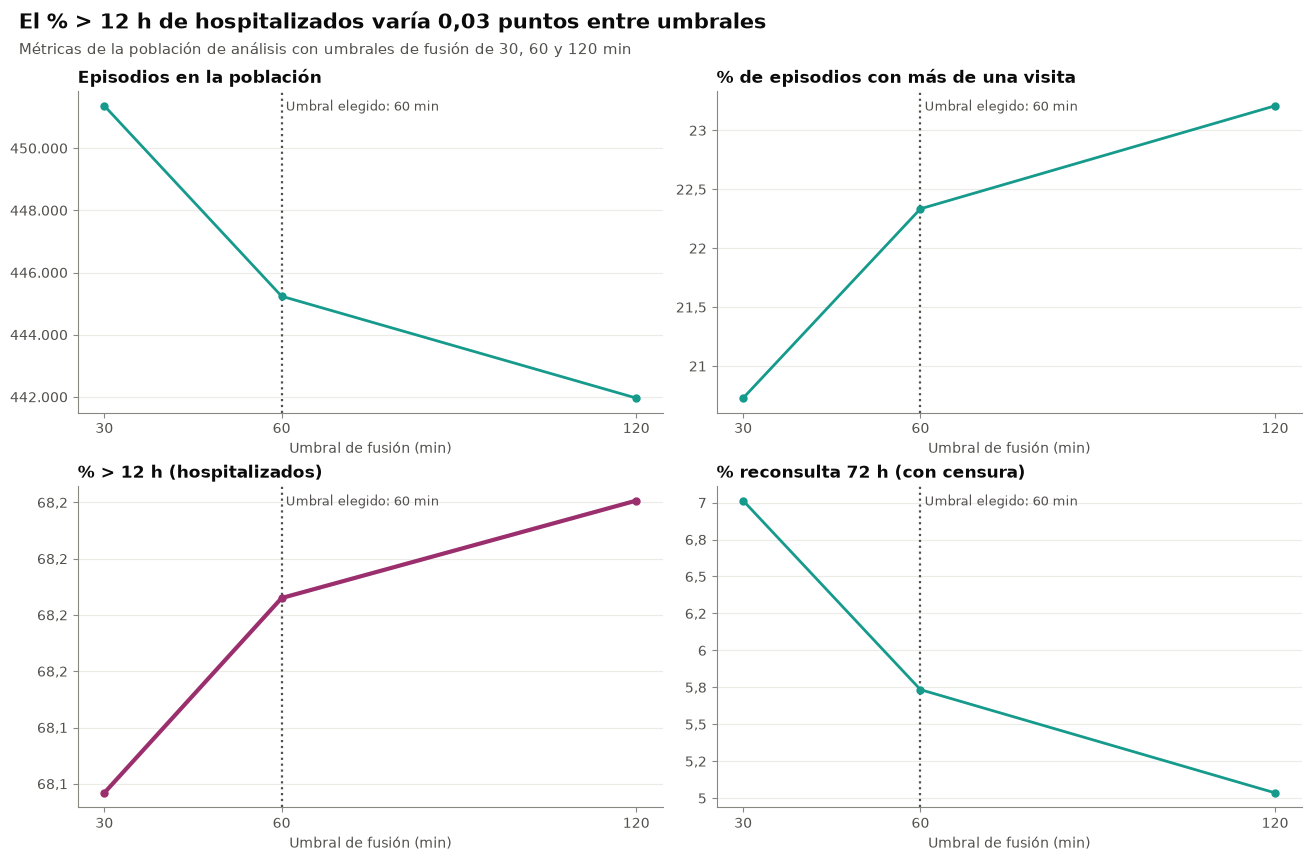

In [16]:
metricas = {
    'n_episodios': 'Episodios en la población',
    'pct_multivisita': '% de episodios con más de una visita',
    columna_12h: f'% > {config.UMBRAL_OPERATIVO_H} h (hospitalizados)',
    'pct_reconsulta_72h_con_censura': '% reconsulta 72 h (con censura)',
}
fig, ejes = plt.subplots(2, 2, figsize=(13, 8.5))
for ax, (columna, titulo) in zip(ejes.ravel(), metricas.items()):
    color = COLOR_HOSP if columna == columna_12h else estilo.VERDE
    ax.plot(sensibilidad.index, sensibilidad[columna], marker='o', color=color,
            linewidth=3 if columna == columna_12h else 2)
    linea_umbral(ax, config.UMBRAL_FUSION_MIN, 'Umbral elegido: 60 min')
    ax.set_xticks(list(sensibilidad.index))
    ax.set_xlabel('Umbral de fusión (min)')
    ax.set_title(titulo)
titulo_hallazgo(fig, f'El % > {config.UMBRAL_OPERATIVO_H} h de hospitalizados varía {fmt_decimal(variacion_pp, 2)} puntos entre umbrales',
                'Métricas de la población de análisis con umbrales de fusión de 30, 60 y 120 min')
guardar_figura(fig, '02_sensibilidad_umbral')
plt.show()

### 8.3 Episodios con el umbral de 60 minutos y comparación informativa con DBeaver

La referencia de DBeaver (sección 2.6) usó las reglas anteriores: sin visitas sin etapas, sin corte temporal y con otra definición de hospitalizado. Para acercarse, `valores_comparables` usa todos los episodios sin corte y excluye los que no tienen etapas. **Las diferencias son esperables y no son un error**; sirven para ver el orden de magnitud.

In [17]:
episodios = construir_episodios(visitas, config.UMBRAL_FUSION_MIN)

comparacion = pd.DataFrame(
    {
        'referencia_dbeaver': pd.Series(config.REFERENCIA_SQL_60MIN, dtype=float),
        'reglas_nuevas': pd.Series(valores_comparables(episodios), dtype=float),
    }
).rename_axis('metrica')
comparacion['diferencia'] = comparacion['reglas_nuevas'] - comparacion['referencia_dbeaver']
suprimir_pequenos(comparacion.round(2), [])

,referencia_dbeaver,reglas_nuevas,diferencia
metrica,,,
episodios,440.202,440.193,-9
hosp_con_hora_piso,36.382,36.384,2
mediana_los_hosp_h,24,"24,02","0,02"
pct_mas_12h_hosp,"68,20","68,16","-0,04"
pct_mas_24h_hosp,50,"50,04","0,04"
mediana_los_atencion_h,7,"6,72","-0,28"
pct_mas_12h_atencion,28,"27,27","-0,73"
pct_reconsulta_72h,"5,40","5,68","0,28"


### 8.4 Tamaño de los tres grupos y casos con LOS recortado a 0

In [18]:
fuera = episodios['en_poblacion'].map({True: 'en_poblacion', False: 'fuera_de_poblacion'}).value_counts()
display(suprimir_pequenos(fuera.rename('n_episodios').rename_axis('alcance').to_frame(), ['n_episodios']))

poblacion = episodios[episodios['en_poblacion']]
tamano_grupos = (
    poblacion['grupo'].value_counts()
    .reindex(list(config.GRUPOS), fill_value=0)
    .rename_axis('grupo')
    .rename('n_episodios')
    .to_frame()
)
tamano_grupos = agregar_porcentaje(tamano_grupos, 'n_episodios')
tamano_grupos['n_sin_etapas'] = poblacion.groupby('grupo')['sin_etapas'].sum().reindex(tamano_grupos.index, fill_value=0)
tamano_grupos['n_multivisita'] = poblacion['n_visitas'].gt(1).groupby(poblacion['grupo']).sum().reindex(tamano_grupos.index, fill_value=0)
display(tabla_segura(tamano_grupos))

display(tabla_segura(contar_los_recortados(poblacion)))

,n_episodios
alcance,
en_poblacion,445.237
fuera_de_poblacion,25.978


,n_episodios,pct_episodios,n_sin_etapas,n_multivisita
grupo,,,,
1_contacto_breve,217.339,"48,8",26.696,27.073
2_atencion_urgencias,193.241,"43,4",<10,61.859
3_hospitalizado,34.657,"7,8",<10,10.509


,n,n_recortados,pct_recortados
grupo,,,
3_hospitalizado,34.657,<10,suprimido


grupo,1_contacto_breve,2_atencion_urgencias,3_hospitalizado
mes,,,
2023-01-01,7.098,5.004,1.008
2023-02-01,6.153,4.527,857
2023-03-01,7.205,5.540,995
2023-04-01,7.030,4.895,1.003
2023-05-01,8.401,5.359,997
2023-06-01,7.173,5.202,967
2023-07-01,7.047,5.268,983
2023-08-01,6.886,5.269,998
2023-09-01,6.174,5.070,897


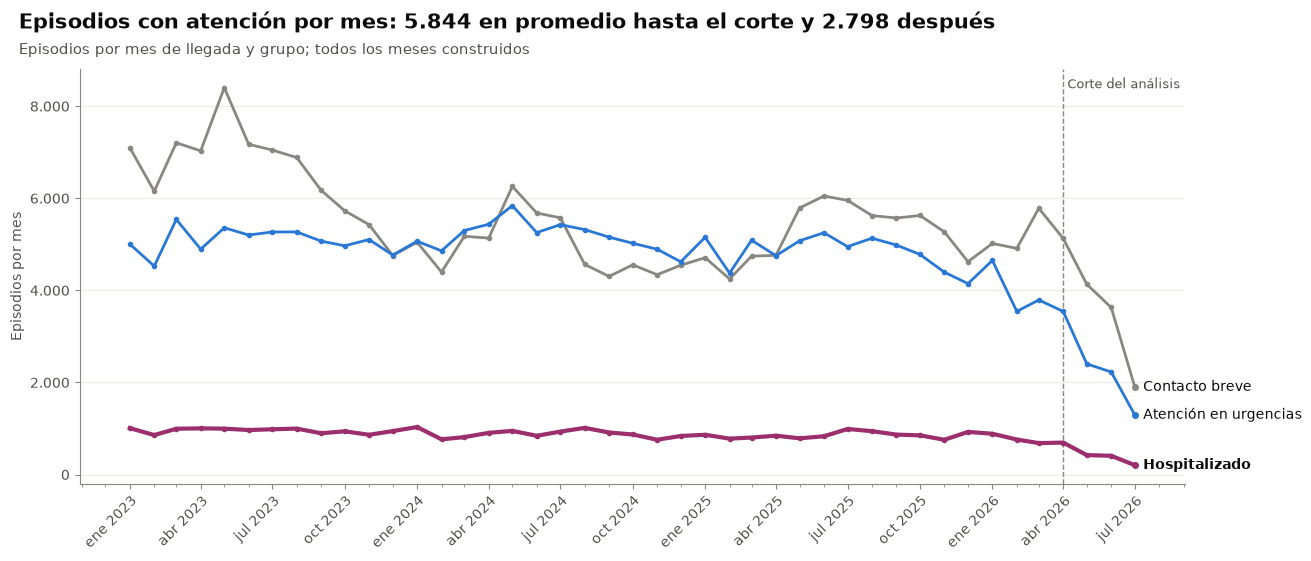

In [19]:
# Episodios por mes y grupo (todos los meses): muestra por qué se corta en marzo de 2026 (D9).
por_mes_grupo = (
    episodios.assign(mes=episodios['llegada'].dt.to_period('M').dt.to_timestamp())
    .groupby(['mes', 'grupo']).size()
    .unstack('grupo', fill_value=0)
    .reindex(columns=list(config.GRUPOS), fill_value=0)
)
display(suprimir_pequenos(por_mes_grupo, list(por_mes_grupo.columns)))

fig, ax = plt.subplots(figsize=(13, 5.5))
for grupo in config.GRUPOS:
    valores = enmascarar_pequenos(por_mes_grupo[grupo], por_mes_grupo[grupo])
    ax.plot(valores.index, valores, marker='o', markersize=3, color=COLORES_GRUPO[grupo], linewidth=ancho_linea(grupo))
    etiquetas_directas(ax, valores.index, {ETIQUETAS_CORTAS_GRUPO[grupo]: (valores, COLORES_GRUPO[grupo])},
                       negrita=[ETIQUETAS_CORTAS_GRUPO[G3]])
marcar_corte(ax)
ax.set_ylabel('Episodios por mes')
con_atencion = por_mes_grupo[[G2, G3]].sum(axis=1)
antes = con_atencion[con_atencion.index <= config.FECHA_CORTE_ANALISIS]
despues = con_atencion[con_atencion.index > config.FECHA_CORTE_ANALISIS]
if not despues.empty:
    titulo = (f'Episodios con atención por mes: {fmt_entero(antes.mean())} en promedio hasta el corte '
              f'y {fmt_entero(despues.mean())} después')
else:
    titulo = 'Episodios de urgencias por mes y grupo'
titulo_hallazgo(fig, titulo, 'Episodios por mes de llegada y grupo; todos los meses construidos')
guardar_figura(fig, '02_episodios_mes_grupo')
plt.show()

## 9. Exportación

In [20]:
nombre_base = f'episodios_urgencias_{config.UMBRAL_FUSION_MIN}min'
config.DATA_INTERIM.mkdir(parents=True, exist_ok=True)
episodios.to_parquet(config.DATA_INTERIM / f'{nombre_base}.parquet', index=False)

metadatos = {
    'umbral_fusion_min': config.UMBRAL_FUSION_MIN,
    'fecha_ejecucion': datetime.now().isoformat(timespec='seconds'),
    'n_filas': int(len(episodios)),
    'n_filas_en_poblacion': int(episodios['en_poblacion'].sum()),
    'n_filas_por_grupo': {g: int(n) for g, n in episodios['grupo'].value_counts().items()},
    'n_filas_por_grupo_en_poblacion': {g: int(n) for g, n in tamano_grupos['n_episodios'].items()},
    'fecha_inicio_analisis': str(config.FECHA_INICIO_ANALISIS),
    'fecha_corte_analisis': str(config.FECHA_CORTE_ANALISIS),
    'sql': 'sql/visitas_urgencias.sql',
    'sha256_sql': hash_sql('visitas_urgencias'),
    'ventanas_reconsulta': list(config.VENTANAS_RECONSULTA),
    'umbrales_los_h': config.UMBRALES_LOS_H,
}
with open(config.DATA_INTERIM / f'{nombre_base}.json', 'w', encoding='utf-8') as archivo:
    json.dump(metadatos, archivo, ensure_ascii=False, indent=2)
print('Exportado:', f'data/interim/{nombre_base}.parquet', 'y', f'data/interim/{nombre_base}.json')

Exportado: data/interim/episodios_urgencias_60min.parquet y data/interim/episodios_urgencias_60min.json
